# Enjambre de Partículas - Implementación en Numpy

In [2]:
# Importar las bibliotecas necesarias
import numpy as np

## Ejemplo de función objetivo
Ejemplo de función objetivo (puedes cambiarla según el caso)


In [4]:
def funcion_objetivo(x):
    return np.sum((x-np.array([1,1.5]))**2) #(x1-1)^2+(x2-1.5)^2

![](https://ars.els-cdn.com/content/image/1-s2.0-S2214579617302915-gr001_lrg.gif)

## Paso 1: Crear matriz de población inicial

Escribe un codigo que genere una población inicial de partículas aleatorias dentro de los límites definidos (limite inferior y superior para cada vaibale).
La población debe tener un tamaño definido por el usuario y cada partícula debe tener una posición aleatoria en el espacio de búsqueda. La matriz debe ser de NxP, donde N es la cantidad de individuos y P es la cantidad de parametros a optimizar.

In [ ]:
N = 1000
P = 2
X = np.zeros((N,P))
limInf = np.array([0,0])
limSup = np.array([3,4])
for n in range(N):
    for p in range(P):
        X[n,p] = (limSup[p]-limInf[p])*np.random.rand()+limInf[p]

Hacer el codigo anterior usando arreglos de Numpy, reemplazar el for anterior por una sola instruccion aprovechando los arreglos de Numpy.

In [ ]:
N = 100
P = 2
X = np.zeros((N,P))
limSup = np.array([3,4])
limInf = np.array([-1,-2])
#Hacer codigo
np.random.seed(42)
X = (limSup-limInf)*np.random.rand(N,P)+limInf

## Paso 2: Evaluar la población usando apply_along_axis

Usa np.apply_along_axis para aplicar una función objetivo a cada partícula de la población.
La función objetivo puede ser cualquier función que se quiera minimizar o maximizar. Almacenar la evaluacion de cada particula en el vector F. Leer la ayuda de la funcion apply_along_axis para entender como se debe emplear.

In [ ]:
F = np.zeros((N,))

In [ ]:
%%timeit
for n in range(N):
  F[n] = funcion_objetivo(X[n,:])

911 µs ± 258 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [ ]:
#Hacer codigo aqui
%%timeit
F = np.apply_along_axis(funcion_objetivo, 1, X)

908 µs ± 5.9 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


## Paso 3: Inicializar las mejores posiciones locales y el mejor global

Almacena las mejores posiciones locales (la mejor posición que cada partícula ha alcanzado) y la mejor global (la mejor de todas las partículas). Cuando se evalua la poblacion es necesario actualizar los valores de los mejores locales y el mejor global. Para saber cual es el mejor global se deben almancenar la posicion y su evaluacion en la funcion objetivo. De igual manera se debe tener un vector con las mejores evaluaciones de cada individuo junto con una matriz con las mejores posiciones. La posicion del mejor global y las posiciones de los mejores locales son utilizadas para el calculo de la velocidad. En este caso solo debemos hacer una copia de la poblacion inicial y de su evaluación en `Pbest` y `Pf`.

In [ ]:
minimo = F[0]
posicion = 0
for n in range(1,N):
  if F[n]<minimo:
    minimo = F[n]
    posicion = n
print(minimo, posicion)

0.20250064802301165 73


In [ ]:
# Almacemar la evaluacion de la funcion objetivo como "Pf" vector de N elementos
Pf = F.copy()

# Almacenar mejores posiciones locales "Pbest" matriz de NxP
Pbest = X.copy()

# Guardar la mejor funcion objetivo, escalar
posmin = np.argmin(F)
fbest = F[posmin]

# Guardar la mejor posicion global, vector de P elementos
gbest = X[posmin,:]

## Paso 4: Calcular la velocidad y actualizar la población

Calcula la nueva velocidad de cada partícula basándote en su posición actual, su mejor posición local y la mejor posición global.
Luego, actualiza la posición de las partículas.

In [ ]:
# Implementar de manera matricial la actualizacion de las posiciones de los individuos vista
# en clase.
V = np.zeros((N,P))
c1, c2 = 0.5, 0.5
r1 = np.random.rand(1,P)
r2 = np.random.rand(1,P)
V = V + c1*r1*(Pbest-X) + c1*r2*(gbest-X)

X = X + V

## Paso 5: Actualizar los mejores locales y el mejor global

Actualiza los mejores valores locales de cada partícula y el mejor global tras la evaluación de la nueva población.

In [ ]:
#Calcular aptitud de individuos nuevos
for n in range(N):
  F[n] = funcion_objetivo(X[n,:])

In [ ]:
# solo actualizar posiciones donde es mejor la local nueva
posCambiar = Pf>F
Pf[posCambiar] = F[posCambiar]
Pbest[posCambiar,:] = X[posCambiar,:]

# Actualiar solo si el nuevo mejor global minimo es mejor que el anterior
posmin = np.argmin(F)
if F[posmin]<fbest:
  fbest = F[posmin]
  gbest = X[posmin,:]


## Paso 6: Realizar los pasos 4 a 5 de manera iterativa

Repite los pasos anteriores durante un número definido de iteraciones o hasta que se alcance un criterio de parada.

In [42]:
#Parametros
N = 10 #Particulas
P = 2  #Cantidad de variables
limSup = np.array([3,4])
limInf = np.array([-1,-2])
iterMax = 1000
c1, c2 = 0.5, 0.5

#Poblacion inicial
np.random.seed(42)
X = (limSup-limInf)*np.random.rand(N,P)+limInf

#Evaluar funcion de aptitud sobre cada individuo
F = np.zeros((N,))
for n in range(N):
  F[n] = funcion_objetivo(X[n,:])

Pf = F.copy()
Pbest = X.copy()
posmin = np.argmin(F)
fbest = F[posmin]
gbest = X[posmin,:]
V = np.zeros((N,P))

for i in range(iterMax):
  r1 = np.random.rand(1,P)
  r2 = np.random.rand(1,P)
  V += c1*r1*(Pbest-X) + c1*r2*(gbest-X)
  X += V

  X = np.clip(X,limInf,limSup)

  for n in range(N):
    F[n] = funcion_objetivo(X[n,:])

  # solo actualizar posiciones donde es mejor la local nueva
  posCambiar = Pf>F
  Pf[posCambiar] = F[posCambiar].copy()
  Pbest[posCambiar,:] = X[posCambiar,:].copy()

  # Actualiar solo si el nuevo mejor global minimo es mejor que el anterior
  posmin = np.argmin(F)
  if F[posmin]<fbest:
    fbest = F[posmin].copy()
    gbest = X[posmin,:].copy()


In [ ]:
#Mejor posicion y su valor de aptitud
gbest,fbest

(array([1.00178482, 1.50396342]), np.float64(1.8894294916224013e-05))

In [91]:
class PSO:
  def __init__(self, funobj, dim, N, limInf, limSup, iterMax, c1=0.5, c2=0.5):
    self.funobj = funobj
    self.dim = dim
    self.N = N
    assert len(limSup) == dim, "La cantidad de variables debe ser igual al tamaño del vector LimSup"
    assert len(limInf) == dim, "La cantidad de variables debe ser igual al tamaño del vector LimInf"
    if type(limSup) is list:
      limSup = np.array(limSup)
    if type(limInf) is list:
      limInf = np.array(limInf)
    self.limSup = limSup
    self.limInf = limInf
    self.c1 = c1
    self.c2 = c2
    assert type(iterMax) is int, "El tipo de dato de la cantidad de iteraciones debe ser entero."
    self.iterMax = iterMax
    self.initPob()

  def initPob(self, seed = 42): #Inicializar poblacion
    np.random.seed(seed)
    self.X = (self.limSup-self.limInf)*np.random.rand(self.N,self.dim)+self.limInf

  def Optimizar(self):
    #Evaluar funcion de aptitud sobre cada individuo
    F = np.zeros((self.N,))
    for n in range(self.N):
      F[n] = self.funobj(self.X[n,:])

    Pf = F.copy()
    Pbest = self.X.copy()
    posmin = np.argmin(F)
    fbest = F[posmin]
    gbest = self.X[posmin,:]
    V = np.zeros((self.N,self.dim))
    historico = np.zeros((self.iterMax,))
    for i in range(self.iterMax):
      r1 = np.random.rand(1,self.dim)
      r2 = np.random.rand(1,self.dim)
      V += self.c1*r1*(Pbest-self.X) + self.c2*r2*(gbest-self.X)
      self.X += V

      self.X = np.clip(self.X,self.limInf,self.limSup)

      for n in range(self.N):
        F[n] = funcion_objetivo(self.X[n,:])

      # solo actualizar posiciones donde es mejor la local nueva
      posCambiar = Pf>F
      Pf[posCambiar] = F[posCambiar].copy()
      Pbest[posCambiar,:] = self.X[posCambiar,:].copy()

      # Actualiar solo si el nuevo mejor global minimo es mejor que el anterior
      posmin = np.argmin(F)
      if F[posmin]<fbest:
        fbest = F[posmin].copy()
        gbest = self.X[posmin,:].copy()

      historico[i] = fbest
    return gbest, fbest, historico

In [94]:
pso1 = PSO(funcion_objetivo, 2, 100, [0,0], [2,2], 1000, 0.5,0.5)
realizaciones = np.zeros((10,1000))
for k in range(10):
  pso1.initPob(k) #Poblacion inicial
  x, fun, historico = pso1.Optimizar()
  realizaciones[k,:] = historico
  print(f"Iteracion {k}, x*={x}, f(x*)={fun}")

Iteracion 0, x*=[1.0012805  1.50213168], f(x*)=6.183753866153962e-06
Iteracion 1, x*=[0.99906726 1.49948133], f(x*)=1.1390179487265947e-06
Iteracion 2, x*=[1.00153598 1.50141507], f(x*)=4.361638621155935e-06
Iteracion 3, x*=[0.99973592 1.50170233], f(x*)=2.967684009672646e-06
Iteracion 4, x*=[0.99907934 1.50031519], f(x*)=9.469617183904518e-07
Iteracion 5, x*=[1.00037919 1.50144376], f(x*)=2.2282183248931015e-06
Iteracion 6, x*=[1.00066937 1.50110884], f(x*)=1.6775933535390994e-06
Iteracion 7, x*=[0.99459689 1.4991933 ], f(x*)=2.9844405605561186e-05
Iteracion 8, x*=[0.99927271 1.50277393], f(x*)=8.223666849097498e-06
Iteracion 9, x*=[0.99962163 1.49887366], f(x*)=1.4118112357943e-06


In [93]:
realizaciones1 = realizaciones.copy()

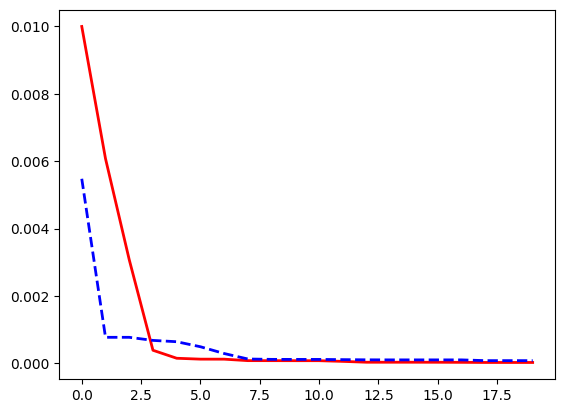

In [95]:
media1 = np.mean(realizaciones1,axis=0)
media2 = np.mean(realizaciones,axis=0)
plt.plot(media1[:20],'r-', linewidth=2)
plt.plot(media2[:20],'b--', linewidth=2)